# CSE 258 Assignment 2: Food.com Recipes and Reviews

**Team:** Arianna Xie, Judy Troung, Danyang Ma, Tom Yang

This notebook goes with our ~20 min video. Graders follow along without running anything, so every section has a short explanation and all outputs (tables, plots) are saved in the notebook.

**Layout.** Setup, then **1. Exploratory Analysis** and **2. Related Work** (shared by all tasks), then one block per task with **3. Predictive Task, 4. Modeling, 5. Evaluation**.

| Task | Owners |
|---|---|
| Task 1: Rating prediction | Arianna & Judy |
| Task 2: *(fill in)* | |
| Task 3: *(fill in)* | |

## Setup (shared)
Shared objects are `train`, `valid`, `test`, `recipes`, `results`, `log_result`, `known_u`, `known_i` and `cold_flags`; treat them as read-only after Section 1. Task-specific names get a prefix (`rt_` for rating prediction) so tasks never overwrite each other. Every model logs scores with `log_result(task, model, split, **metrics)`. Tune on validation only; score the test set once, in each task's Section 5.

In [14]:
# install libraries in the kernal that's running
%pip install numpy pandas matplotlib scipy scikit-learn jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jinja2]2m1/2 [jinja2]
Note: you may need to restart the kernel to use updated packages.


In [8]:
# from google.colab import drive
# drive.mount('/content/drive')

import ast, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
SEED = 0
random.seed(SEED)
np.random.seed(SEED)

DATA_PATH = "../dataset/"
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})

In [9]:
results = []  # one row per (task, model, split); metric columns vary by task

def log_result(task, model, split, **metrics):
    results.append({"task": task, "model": model, "split": split, **metrics})

---
## 1. Exploratory Analysis, Data Collection, and Pre-processing *(shared)*

**About the Dataset:** The dataset has **180K+ recipes** and **700K+ recipe reviews** covering **18 years** of user interactions and uploads on [Food.com](https://www.food.com). It was crawled from Food.com (formerly GeniusKitchen), an online recipe aggregator where users upload recipes (steps, ingredients, cooking time, tags, nutrition) and others review them with a 0-5 star rating and free text. It was released to study personalised recipe generation.

> Majumder, B. P.\*, Li, S.\*, Ni, J., & McAuley, J. (2019). *Generating Personalized Recipes from Historical User Preferences.* EMNLP 2019. https://www.aclweb.org/anthology/D19-1613/

**Dataset Files:** We use `RAW_recipes.csv` (recipe metadata) and `interactions_train/validation/test.csv` (reviews already split **by date** by the authors; columns `user_id, recipe_id, date, rating, u, i`). `RAW_interactions.csv` (full reviews with text) is only needed if a task uses review text. The `PP_*` files are tokenised versions made for the authors' generation model, so we don't use them.

**Exporatory Analysis Approach:** We loaded the data, plotted it to look for outliers, skew, drift and other patterns, and decided what needs processing (summarised in the table before the processing cell).

In [10]:
train = pd.read_csv(DATA_PATH + "interactions_train.csv")
valid = pd.read_csv(DATA_PATH + "interactions_validation.csv")
test  = pd.read_csv(DATA_PATH + "interactions_test.csv")
recipes_raw = pd.read_csv(DATA_PATH + "RAW_recipes.csv")
for d in (train, valid, test):
    d["date"] = pd.to_datetime(d["date"])

print(f"train {len(train):,} | validation {len(valid):,} | test {len(test):,} | recipes {len(recipes_raw):,}")
print(f"Duplicate recipe ids: {len(recipes_raw) - recipes_raw.id.nunique()}")
print(f"Missing values in train interactions: {int(train.isna().sum().sum())}")
print(f"Duplicate (user, recipe) pairs in train: {int(train.duplicated(['user_id', 'recipe_id']).sum())}")
train.head()

train 698,901 | validation 7,023 | test 12,455 | recipes 231,637
Duplicate recipe ids: 0
Missing values in train interactions: 0
Duplicate (user, recipe) pairs in train: 0


,user_id,recipe_id,date,rating,u,i
0,2046,4684,2000-02-25,5.0,22095,44367
1,2046,517,2000-02-25,5.0,22095,87844
2,1773,7435,2000-03-13,5.0,24732,138181
3,1773,278,2000-03-13,4.0,24732,93054
4,2046,3431,2000-04-07,5.0,22095,101723


**Ratings and time.** What do the labels look like, and does anything drift over the 18 years? Dashed lines mark where validation and test begin.

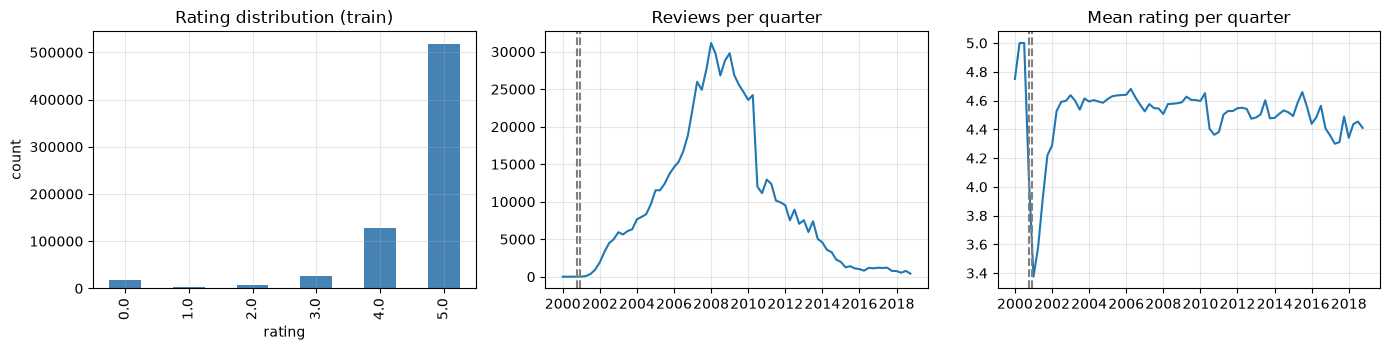

mean 4.574 | variance 0.920 | share of 0-star ratings 2.4% | share of 5-star 74.2%


In [11]:
allx = pd.concat([train, valid, test])
q = allx.set_index("date").rating.resample("QS").agg(["count", "mean"])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
train.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Rating distribution (train)"); ax[0].set_xlabel("rating"); ax[0].set_ylabel("count")
ax[1].plot(q.index, q["count"]); ax[1].set_title("Reviews per quarter")
ax[2].plot(q.index, q["mean"]); ax[2].set_title("Mean rating per quarter")
for a in ax[1:]:
    a.axvline(valid.date.min(), c="gray", ls="--"); a.axvline(test.date.min(), c="gray", ls="--")
plt.tight_layout(); plt.show()
print(f"mean {train.rating.mean():.3f} | variance {train.rating.var():.3f} | share of 0-star ratings {(train.rating == 0).mean():.1%} | share of 5-star {(train.rating == 5).mean():.1%}")

**Users and recipes.** How much activity does each have, and do users/recipes differ in how they rate? (Averages use users/recipes with at least 5 reviews.) A long tail means per-user and per-recipe parameters need regularisation; a wide spread in averages means identity carries real signal.

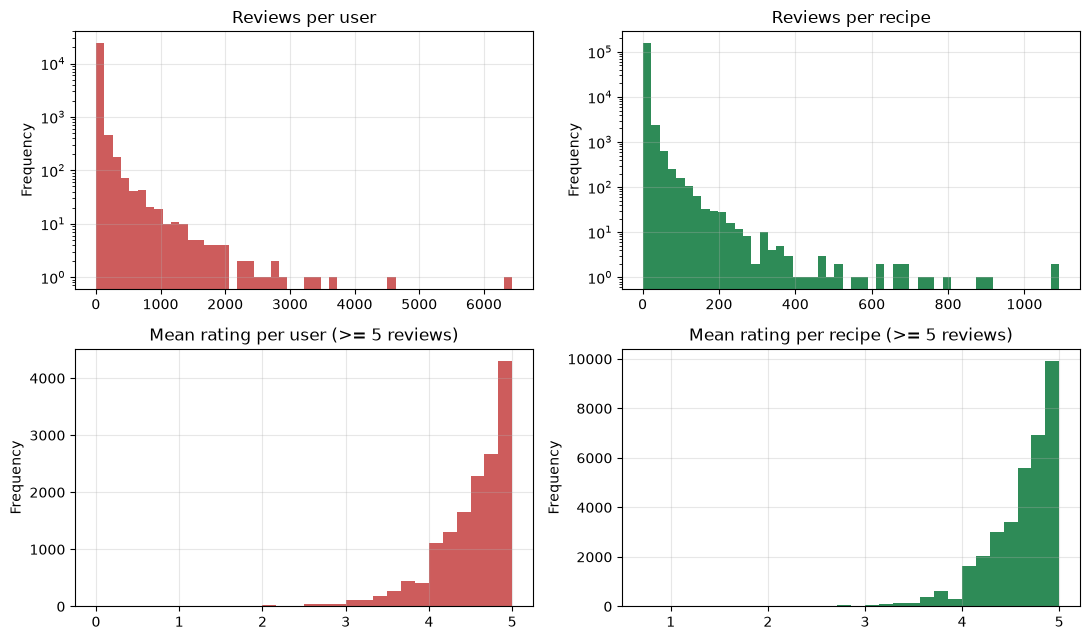

Users with 1 review: 0.0% (median 6) | Recipes with 1 review: 41.3% (median 2)


In [12]:
uc = train.groupby("user_id").rating.agg(["count", "mean"])
ic = train.groupby("recipe_id").rating.agg(["count", "mean"])

fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))
uc["count"].plot.hist(bins=50, log=True, ax=ax[0, 0], color="indianred"); ax[0, 0].set_title("Reviews per user")
ic["count"].plot.hist(bins=50, log=True, ax=ax[0, 1], color="seagreen"); ax[0, 1].set_title("Reviews per recipe")
uc[uc["count"] >= 5]["mean"].plot.hist(bins=30, ax=ax[1, 0], color="indianred"); ax[1, 0].set_title("Mean rating per user (>= 5 reviews)")
ic[ic["count"] >= 5]["mean"].plot.hist(bins=30, ax=ax[1, 1], color="seagreen"); ax[1, 1].set_title("Mean rating per recipe (>= 5 reviews)")
plt.tight_layout(); plt.show()
print(f"Users with 1 review: {(uc['count'] == 1).mean():.1%} (median {uc['count'].median():.0f}) | Recipes with 1 review: {(ic['count'] == 1).mean():.1%} (median {ic['count'].median():.0f})")

**Splits and cold start.** The split is by date, so every task predicts the future from the past. Some validation/test users and recipes never appear in train (cold start), so every model needs a fallback for them.

In [15]:
known_u, known_i = set(train.user_id), set(train.recipe_id)

def cold_flags(df):
    return pd.DataFrame({"cold_user": ~df.user_id.isin(known_u),
                         "cold_item": ~df.recipe_id.isin(known_i)}, index=df.index)

split_info = pd.DataFrame({
    "rows": [len(d) for d in (train, valid, test)],
    "first date": [d.date.min().date() for d in (train, valid, test)],
    "last date": [d.date.max().date() for d in (train, valid, test)],
    "cold-start users": [0.0] + [cold_flags(d).cold_user.mean() for d in (valid, test)],
    "cold-start recipes": [0.0] + [cold_flags(d).cold_item.mean() for d in (valid, test)],
}, index=["train", "validation", "test"])
split_info.style.format({"cold-start users": "{:.1%}", "cold-start recipes": "{:.1%}"})

,rows,first date,last date,cold-start users,cold-start recipes
train,698901,2000-02-25,2018-12-19,0.0%,0.0%
validation,7023,2000-12-06,2018-12-11,0.0%,100.0%
test,12455,2000-10-05,2018-12-18,0.0%,100.0%


**Recipe metadata.** Distributions of the raw cooking time, number of steps and number of ingredients, to spot outliers. Cooking time is on a log axis because of its range.

            minutes   n_steps  n_ingredients
count  2.316370e+05  231637.0       231637.0
mean   9.398500e+03       9.8            9.1
std    4.461963e+06       6.0            3.7
min    0.000000e+00       0.0            1.0
50%    4.000000e+01       9.0            9.0
99%    9.039000e+02      30.0           20.0
max    2.147484e+09     145.0           43.0
Missing values: 0
minutes == 0: 1094 | > 1 day: 2000 | > 1 year: 2


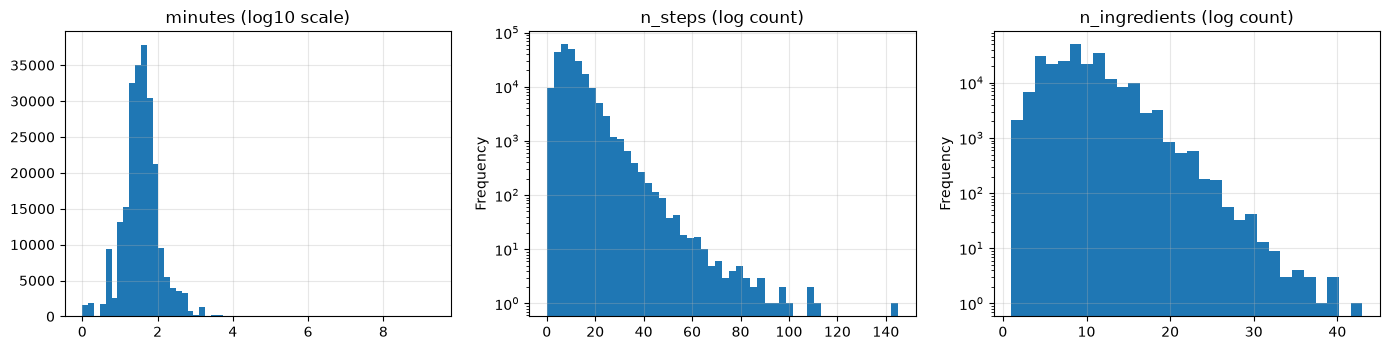

In [16]:
meta_cols = ["minutes", "n_steps", "n_ingredients"]
print(recipes_raw[meta_cols].describe(percentiles=[.5, .99]).round(1))
print(f"Missing values: {int(recipes_raw[meta_cols + ['ingredients']].isna().sum().sum())}")
print(f"minutes == 0: {(recipes_raw.minutes == 0).sum()} | > 1 day: {(recipes_raw.minutes > 1440).sum()} | > 1 year: {(recipes_raw.minutes > 525600).sum()}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(np.log10(recipes_raw.minutes.clip(lower=1)), bins=60); ax[0].set_title("minutes (log10 scale)")
recipes_raw.n_steps.plot.hist(bins=50, log=True, ax=ax[1]); ax[1].set_title("n_steps (log count)")
recipes_raw.n_ingredients.plot.hist(bins=30, log=True, ax=ax[2]); ax[2].set_title("n_ingredients (log count)")
plt.tight_layout(); plt.show()

**Do recipe features relate to ratings?** Mean rating (with 95% interval) across deciles of each feature, using the raw values. Deciles are by rank, so outliers don't distort the bins.

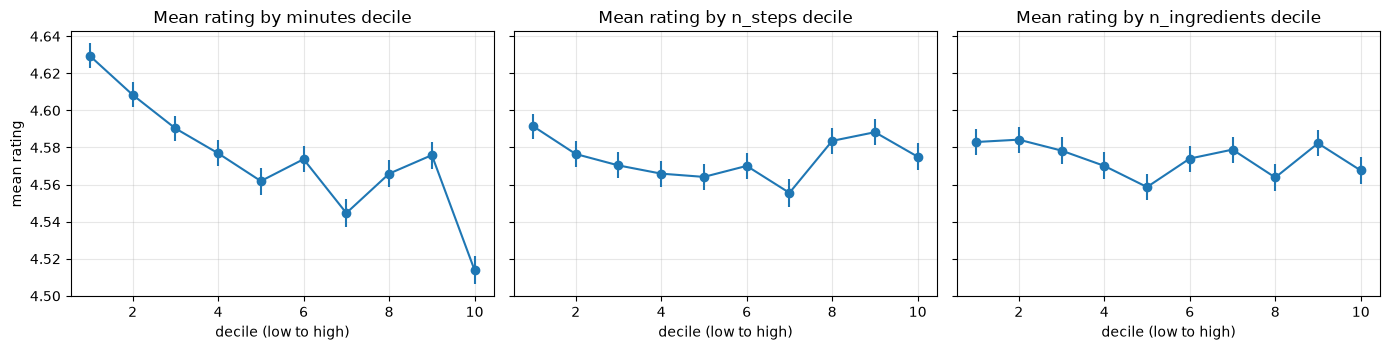

In [17]:
tr = train.merge(recipes_raw.drop_duplicates("id")[["id"] + meta_cols], left_on="recipe_id", right_on="id", how="left")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, c in zip(ax, meta_cols):
    b = pd.qcut(tr[c].rank(method="first"), 10, labels=False)
    g = tr.groupby(b).rating.agg(["mean", "sem"])
    a.errorbar(g.index + 1, g["mean"], yerr=1.96 * g["sem"], marker="o")
    a.set_title(f"Mean rating by {c} decile"); a.set_xlabel("decile (low to high)")
ax[0].set_ylabel("mean rating"); plt.tight_layout(); plt.show()

**What the plots tell us and what we do about it.** *(Edit the "Observation" column to match what your plots actually show.)*

| Observation | Decision |
|---|---|
| Ratings are skewed toward 5 (and include some 0s) | Keep all labels as given, no filtering. Use MSE and always compare with the global mean. |
| Review volume and mean rating drift over time | Use the provided **time-based** split; tune on validation (closest in time to test). |
| Users and recipes have long-tailed activity, and their average ratings vary widely | Do **not** filter low-activity users. Use **regularised** user/recipe parameters. |
| Some validation/test users and recipes are unseen | Fall back to the global mean / zero bias. Report cold-start errors separately. |
| `minutes` has extreme outliers (up to millions) | **Clip at the 99th percentile, then `log1p`.** |
| `n_steps`, `n_ingredients` have a mild right tail | **Clip at the 99th percentile.** |
| Mean rating changes only weakly across feature deciles | Expect features to add little on their own. Test this with a features-only vs. hybrid comparison. |
| `ingredients` is stored as a string | **Parse** it into a list. |

In [ ]:
recipes = recipes_raw.drop_duplicates("id").reset_index(drop=True)

cap_minutes = recipes.minutes.quantile(0.99)
recipes["log_minutes"] = np.log1p(recipes.minutes.clip(upper=cap_minutes))
for c in ("n_steps", "n_ingredients"):
    recipes[c + "_clip"] = recipes[c].clip(upper=recipes[c].quantile(0.99))
recipes["ing_list"] = recipes.ingredients.apply(ast.literal_eval)

before_after = pd.DataFrame({
    "before (max)": [recipes.minutes.max(), recipes.n_steps.max(), recipes.n_ingredients.max()],
    "after (max)": [recipes.log_minutes.max(), recipes.n_steps_clip.max(), recipes.n_ingredients_clip.max()],
}, index=["minutes -> log1p(clipped)", "n_steps", "n_ingredients"])
print(f"Dropped {len(recipes_raw) - len(recipes)} duplicate recipe ids; minutes clipped at {cap_minutes:.0f}")
display(before_after.round(2))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
recipes.minutes.clip(upper=cap_minutes).plot.hist(bins=50, ax=ax[0]); ax[0].set_title("minutes, clipped (before log)")
recipes.log_minutes.plot.hist(bins=50, ax=ax[1]); ax[1].set_title("log(1 + minutes) after clipping")
plt.tight_layout(); plt.show()

---
## 2. Related Work *(shared)*

**How this dataset has been used.** Majumder et al. (2019) introduced it for **personalised recipe generation**: given a recipe name, a few ingredients and a user's history, generate a full recipe conditioned on that user's preferences. Ratings and reviews act as a signal of taste rather than as the prediction target. *(Add 1-2 other papers you actually read, e.g. on recipe healthiness or popularity.)*

**How prior work approaches our tasks.**
- *Task 1, rating prediction:* matrix factorisation with user and item bias terms is the standard approach (Koren et al., 2009), and Koren (2008) shows bias terms alone capture much of the signal. Hybrid models add item content to handle cold-start items. Our bias model, latent factor model and hybrid follow these ideas.
- *Task 2 / Task 3:* *(fill in)*

**How our results compare.** *(Fill in after each task's Section 5.)* For Task 1: published results on movie data typically show clear gains of latent factors over bias-only models; on Food.com the skew toward 5 stars and sparse per-user histories limit the gain. Say whether our results agree.

**References**
1. Majumder, B. P., Li, S., Ni, J., & McAuley, J. (2019). *Generating Personalized Recipes from Historical User Preferences.* EMNLP-IJCNLP 2019.
2. Koren, Y., Bell, R., & Volinsky, C. (2009). *Matrix Factorization Techniques for Recommender Systems.* IEEE Computer, 42(8), 30-37.
3. Koren, Y. (2008). *Factorization Meets the Neighborhood: A Multifaceted Collaborative Filtering Model.* KDD 2008.

---
## Task 1: Rating Prediction
*Owners: Arianna & Judy.*

### 3. Predictive Task

**Task.** Predict the rating $r_{u,i} \in \{0,1,2,3,4,5\}$ that user $u$ gives to recipe $i$, using the user and recipe identities plus recipe content features: cooking time (`minutes`), number of steps (`n_steps`), number of ingredients (`n_ingredients`) and the ingredient list.

**Evaluation.** Mean squared error (MSE), also reported as RMSE and MAE. MSE is the standard metric for rating prediction in this course and penalises large misses (predicting 5 for a 1-star review) more than small ones. Full justification in Section 5.

**Baselines.**
- Trivial: global mean rating; user mean; recipe mean.
- From class: regularised bias model $\hat r_{u,i} = \alpha + \beta_u + \beta_i$ and a latent factor model $\alpha + \beta_u + \beta_i + \gamma_u \cdot \gamma_i$.
- Our content-based models: ridge regression on recipe features, and a hybrid that fits ridge regression on the *residuals* of the bias model.

**Validity.**
- We use the dataset's own **time-based** train / validation / test split, so we always predict the future from the past, as a deployed system would.
- Hyperparameters are tuned on validation only; the test set is scored **once**, in Section 5.
- Recipe features are properties of the recipe, not of the rating, so there is no label leakage. Any statistic that uses ratings (user and recipe means, biases) is computed on train only.
- Sanity checks: all models are compared against the global mean, predictions are clipped to [1, 5], and we report errors separately for warm-start and cold-start users/recipes.

### 4. Modeling

**Context.** Inputs are a (user, recipe) pair plus recipe content features; the output is a rating in [1, 5]. Every model minimises squared error on train (with L2 regularisation), and the same MSE is the evaluation metric, so the training objective matches what we report.

**Models, in order of complexity.**

| Model | Uses | Pros | Cons |
|---|---|---|---|
| Global / user / recipe mean | identity only | trivial, no tuning | no personalisation, or very noisy for rarely-seen users/recipes |
| Bias model $\alpha+\beta_u+\beta_i$ | identity | cheap, regularised, strong baseline | cannot model user-recipe interaction; cold-start falls back to $\alpha$ |
| Ridge on recipe features | content | works for **cold-start recipes**; interpretable | recipe features only; no user information |
| Bias + ridge on residuals (hybrid) | identity + content | features add what biases miss, and cover cold-start recipes | residuals are computed in-sample, so slightly shrunk |
| Latent factor model | identity | captures user-recipe interaction | many parameters, needs tuning, slow in pure numpy, noisy with sparse users |

**Implementation notes.** Every model is a pair of functions: `fit_*` returns parameters and `predict_*` returns clipped predictions. Nothing mutates globals, so cells can be re-run in any order.

**Features.** From the processed recipe table in Section 1 we use log-minutes, clipped steps and clipped ingredient count (standardised), plus binary indicators for the 300 most common ingredients. Recipes missing from the table get an all-zero row (the mean after standardisation). These are properties of the recipe, not of any rating, so building them from all recipes is not leakage.

In [ ]:
rt_NUM_COLS = ["log_minutes", "n_steps_clip", "n_ingredients_clip"]
rt_N_ING = 300
rt_vec = CountVectorizer(analyzer=lambda x: x, max_features=rt_N_ING, binary=True)
rt_ING = rt_vec.fit_transform(recipes.ing_list)
rt_num = StandardScaler().fit_transform(recipes[rt_NUM_COLS])

rt_zero_row = lambda M: sp.vstack([M, sp.csr_matrix((1, M.shape[1]))]).tocsr()  # extra row = unknown recipe
rt_F_basic = rt_zero_row(sp.csr_matrix(rt_num))
rt_F_full  = rt_zero_row(sp.hstack([sp.csr_matrix(rt_num), rt_ING]).tocsr())
rt_row_of = pd.Series(np.arange(len(recipes)), index=recipes.id)

def rt_rows(df):
    return df.recipe_id.map(rt_row_of).fillna(len(recipes)).astype(int).values
def rt_X_basic(df): return rt_F_basic[rt_rows(df)]
def rt_X_full(df):  return rt_F_full[rt_rows(df)]

print(f"Train interactions whose recipe is missing from RAW_recipes: {(~train.recipe_id.isin(rt_row_of.index)).mean():.2%}")
print("Feature matrix shapes (basic / full):", rt_F_basic.shape, rt_F_full.shape)

**Data split and evaluation helper**
We use the dataset's pre-made time-based split loaded in Section 1 (no random shuffling). `rt_evaluate` computes MSE, RMSE and MAE and writes them to the shared `results` list with `task="rating"`.

In [ ]:
RT = "rating"

def rt_evaluate(name, y_true, y_pred, split="val"):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mse = mean_squared_error(y_true, y_pred)
    log_result(RT, name, split, MSE=mse, RMSE=mse ** 0.5, MAE=np.abs(y_true - y_pred).mean())
    return mse

print(f"train {len(train):,} | validation {len(valid):,} | test {len(test):,}")

**Baselines: global, user and recipe mean**

In [ ]:
rt_global_mean = train.rating.mean()
rt_user_mean = train.groupby("user_id").rating.mean()
rt_item_mean = train.groupby("recipe_id").rating.mean()

def rt_pred_global(df): return np.full(len(df), rt_global_mean)
def rt_pred_user_mean(df): return df.user_id.map(rt_user_mean).fillna(rt_global_mean).values
def rt_pred_item_mean(df): return df.recipe_id.map(rt_item_mean).fillna(rt_global_mean).values

for name, fn in [("Global mean", rt_pred_global), ("User mean", rt_pred_user_mean), ("Recipe mean", rt_pred_item_mean)]:
    print(f"{name:12s} val MSE = {rt_evaluate(name, valid.rating, fn(valid), 'val'):.4f}")

**Bias model**
$\hat r_{u,i} = \alpha + \beta_u + \beta_i$, fit by alternating closed-form updates with L2 penalties $\lambda_u, \lambda_i$:
$\beta_u = \frac{\sum_i (r_{u,i} - \alpha - \beta_i)}{\lambda_u + |I_u|}$ (and symmetrically for $\beta_i$). The penalty shrinks biases of users/recipes with few reviews toward 0, which is exactly what fixes the noise of the raw user/recipe means above. Unseen users/recipes get $\beta = 0$.

In [ ]:
def rt_fit_bias(train, lam_u=5, lam_i=5, iters=10):
    alpha = train.rating.mean()
    b_u, b_i = pd.Series(dtype=float), pd.Series(dtype=float)
    for _ in range(iters):
        r = train.rating - alpha - train.recipe_id.map(b_i).fillna(0)
        g = r.groupby(train.user_id)
        b_u = g.sum() / (lam_u + g.count())
        r = train.rating - alpha - train.user_id.map(b_u).fillna(0)
        g = r.groupby(train.recipe_id)
        b_i = g.sum() / (lam_i + g.count())
    return alpha, b_u, b_i

def rt_predict_bias(df, params, clip=True):
    alpha, b_u, b_i = params
    p = alpha + df.user_id.map(b_u).fillna(0).values + df.recipe_id.map(b_i).fillna(0).values
    return np.clip(p, 1, 5) if clip else p

rt_bias_params = rt_fit_bias(train, 5, 5)
print(f"Bias model (lambda=5, 5) val MSE = {mean_squared_error(valid.rating, rt_predict_bias(valid, rt_bias_params)):.4f}")

**Features-only model (ridge regression)**
$\hat r_{u,i} = \theta \cdot x_i$ where $x_i$ is the recipe feature vector. We try two feature sets: (a) 3 numeric features (log minutes, steps, number of ingredients) and (b) those plus 300 binary ingredient indicators. This model knows nothing about *who* is rating, so it can only learn "what kind of recipe tends to get higher ratings".

In [ ]:
def rt_fit_feat(df, Xfn, alpha):
    return Ridge(alpha=alpha).fit(Xfn(df), df.rating)

def rt_predict_feat(df, model, Xfn):
    return np.clip(model.predict(Xfn(df)), 1, 5)

for name, Xfn in [("Ridge, 3 numeric features", rt_X_basic), ("Ridge, numeric + 300 ingredients", rt_X_full)]:
    m = rt_fit_feat(train, Xfn, alpha=10)
    print(f"{name:35s} val MSE = {mean_squared_error(valid.rating, rt_predict_feat(valid, m, Xfn)):.4f}")

**Main model: bias model + recipe features (hybrid)**
We fit ridge regression on the **residuals** $r_{u,i} - (\alpha + \beta_u + \beta_i)$ from the bias model, so the features only have to explain what identity effects miss:
$\hat r_{u,i} = \alpha + \beta_u + \beta_i + \theta \cdot x_i$.
This isolates exactly what the recipe features add beyond user and recipe effects. We expect the gain to be largest for cold-start recipes (where $\beta_i = 0$), and small for well-reviewed ones where $\beta_i$ already encodes everything about the recipe.

In [ ]:
def rt_fit_combined(train, rt_bias_params, Xfn, alpha):
    resid = train.rating.values - rt_predict_bias(train, rt_bias_params, clip=False)
    return Ridge(alpha=alpha).fit(Xfn(train), resid)

def rt_predict_combined(df, rt_bias_params, ridge, Xfn):
    return np.clip(rt_predict_bias(df, rt_bias_params, clip=False) + ridge.predict(Xfn(df)), 1, 5)

rt_hyb = rt_fit_combined(train, rt_bias_params, rt_X_full, alpha=10)
print(f"Hybrid (bias + numeric + ingredients) val MSE = {mean_squared_error(valid.rating, rt_predict_combined(valid, rt_bias_params, rt_hyb, rt_X_full)):.4f}")

**Latent factor model**
$\hat r_{u,i} = \alpha + \beta_u + \beta_i + \gamma_u \cdot \gamma_i$, with $k$-dimensional factors $\gamma$. We train with mini-batch SGD on squared error with L2 regularisation `reg` on all parameters, implemented directly in numpy (`np.add.at` handles repeated users/recipes in a batch). After every epoch we score validation and keep the best epoch (early stopping). Users/recipes not seen in train point to an all-zero row, so they fall back to $\alpha$, exactly like the bias model.

*Trade-off:* it can capture taste interactions the bias model cannot, but with most users having very few reviews the factors are poorly determined, so it needs strong regularisation and may not beat the bias model by much.

In [ ]:
def rt_fit_lfm(train, valid, k=16, lr=0.01, reg=0.05, epochs=15, bs=512, seed=SEED):
    rng = np.random.default_rng(seed)
    uix = pd.Series(np.arange(train.user_id.nunique()), index=train.user_id.unique())
    iix = pd.Series(np.arange(train.recipe_id.nunique()), index=train.recipe_id.unique())
    nu, ni = len(uix), len(iix)
    m = {"mu": train.rating.mean(), "uix": uix, "iix": iix, "nu": nu, "ni": ni,
         "bu": np.zeros(nu + 1), "bi": np.zeros(ni + 1),          # extra last row = unseen id (stays 0)
         "P": np.zeros((nu + 1, k)), "Q": np.zeros((ni + 1, k))}
    m["P"][:nu] = rng.normal(0, 0.1, (nu, k)); m["Q"][:ni] = rng.normal(0, 0.1, (ni, k))
    u_tr = train.user_id.map(uix).values; i_tr = train.recipe_id.map(iix).values
    r = train.rating.values.astype(float)
    bu, bi, P, Q, mu = m["bu"], m["bi"], m["P"], m["Q"], m["mu"]

    best_mse, best_state, best_ep, history = np.inf, None, 0, []
    for ep in range(epochs):
        perm = rng.permutation(len(r))
        for s in range(0, len(r), bs):
            b = perm[s:s + bs]; u, i = u_tr[b], i_tr[b]
            pu, qi = P[u], Q[i]
            e = r[b] - (mu + bu[u] + bi[i] + (pu * qi).sum(1))
            np.add.at(bu, u, lr * (e - reg * bu[u]))
            np.add.at(bi, i, lr * (e - reg * bi[i]))
            np.add.at(P, u, lr * (e[:, None] * qi - reg * pu))
            np.add.at(Q, i, lr * (e[:, None] * pu - reg * qi))
        val_mse = mean_squared_error(valid.rating, rt_predict_lfm(valid, m))
        history.append(val_mse)
        if val_mse < best_mse:
            best_mse, best_ep = val_mse, ep + 1
            best_state = [a.copy() for a in (bu, bi, P, Q)]
        elif ep + 1 - best_ep >= 2:      # no improvement for 2 epochs -> stop
            break
    m["bu"], m["bi"], m["P"], m["Q"] = best_state
    m["best_epoch"], m["history"] = best_ep, history
    return m

def rt_predict_lfm(df, m):
    u = df.user_id.map(m["uix"]).fillna(m["nu"]).astype(int).values
    i = df.recipe_id.map(m["iix"]).fillna(m["ni"]).astype(int).values
    return np.clip(m["mu"] + m["bu"][u] + m["bi"][i] + (m["P"][u] * m["Q"][i]).sum(1), 1, 5)

rt_lfm = rt_fit_lfm(train, valid, k=16, reg=0.05)
plt.plot(range(1, len(rt_lfm["history"]) + 1), rt_lfm["history"], marker="o")
plt.axvline(rt_lfm["best_epoch"], ls="--", c="gray")
plt.title("LFM validation MSE per epoch (k=16, reg=0.05)"); plt.xlabel("epoch"); plt.ylabel("val MSE"); plt.show()
print(f"LFM val MSE = {min(rt_lfm['history']):.4f} at epoch {rt_lfm['best_epoch']}")

**Hyperparameter tuning (on validation set)**
All tuning uses the **validation set only**:
- Bias model: grid over $(\lambda_u, \lambda_i)$.
- Ridge (features only): feature set and ridge strength.
- Hybrid: feature set and ridge strength, on top of the best bias model.
- LFM: regularisation, then number of factors $k$. *(This is the slowest cell, expect several minutes.)*

In [ ]:
# Bias model: grid over (lambda_u, lambda_i)
grid = [1, 3, 10, 30]
bias_tbl = pd.DataFrame(index=grid, columns=grid, dtype=float)
for lu in grid:
    for li in grid:
        bias_tbl.loc[lu, li] = mean_squared_error(valid.rating, rt_predict_bias(valid, rt_fit_bias(train, lu, li)))
bias_tbl.index.name, bias_tbl.columns.name = "lambda_u", "lambda_i"
display(bias_tbl.round(4))
best_lu, best_li = bias_tbl.stack().idxmin()
print(f"Best bias model: lambda_u={best_lu}, lambda_i={best_li}, val MSE={bias_tbl.stack().min():.4f}")
rt_best_bias_params = rt_fit_bias(train, best_lu, best_li)

In [ ]:
# Ridge strength and feature set: features-only and hybrid
alphas = [0.1, 1, 10, 100, 1000]
rows_ = []
for fs_name, Xfn in [("numeric", rt_X_basic), ("numeric+ingredients", rt_X_full)]:
    for a in alphas:
        m1 = rt_fit_feat(train, Xfn, a)
        m2 = rt_fit_combined(train, rt_best_bias_params, Xfn, a)
        rows_.append({"features": fs_name, "alpha": a,
                      "features-only val MSE": mean_squared_error(valid.rating, rt_predict_feat(valid, m1, Xfn)),
                      "hybrid val MSE": mean_squared_error(valid.rating, rt_predict_combined(valid, rt_best_bias_params, m2, Xfn))})
ridge_tbl = pd.DataFrame(rows_)
display(ridge_tbl.round(4))
bf = ridge_tbl.loc[ridge_tbl["features-only val MSE"].idxmin()]
bh = ridge_tbl.loc[ridge_tbl["hybrid val MSE"].idxmin()]
print("Best features-only:", bf["features"], bf["alpha"], "| Best hybrid:", bh["features"], bh["alpha"])

In [ ]:
# Latent factor model: regularisation, then k
lfm_rows, rt_lfm_models = [], {}
for reg in [0.02, 0.05, 0.1]:
    mdl = rt_fit_lfm(train, valid, k=16, reg=reg); rt_lfm_models[(16, reg)] = mdl
    lfm_rows.append({"k": 16, "reg": reg, "val MSE": min(mdl["history"]), "best epoch": mdl["best_epoch"]})
best_reg = min(lfm_rows, key=lambda d: d["val MSE"])["reg"]
for k in [4, 8, 32]:
    mdl = rt_fit_lfm(train, valid, k=k, reg=best_reg); rt_lfm_models[(k, best_reg)] = mdl
    lfm_rows.append({"k": k, "reg": best_reg, "val MSE": min(mdl["history"]), "best epoch": mdl["best_epoch"]})
lfm_tbl = pd.DataFrame(lfm_rows)
display(lfm_tbl.round(4))
rt_best_lfm_key = min(rt_lfm_models, key=lambda key: min(rt_lfm_models[key]["history"]))
rt_best_lfm = rt_lfm_models[rt_best_lfm_key]
print("Best LFM (k, reg):", rt_best_lfm_key)

**Final fits.** Re-fit each model with its best hyperparameters (train only) and log validation scores. These are the models carried into Section 5.

In [ ]:
Xfn_feat = rt_X_full if bf["features"] == "numeric+ingredients" else rt_X_basic
Xfn_hyb  = rt_X_full if bh["features"] == "numeric+ingredients" else rt_X_basic
rt_feat_model = rt_fit_feat(train, Xfn_feat, bf["alpha"])
rt_hyb_model  = rt_fit_combined(train, rt_best_bias_params, Xfn_hyb, bh["alpha"])

rt_final_models = {
    "Global mean":                   rt_pred_global,
    "User mean":                     rt_pred_user_mean,
    "Recipe mean":                   rt_pred_item_mean,
    "Bias model":                    lambda df: rt_predict_bias(df, rt_best_bias_params),
    "Ridge (recipe features only)":  lambda df: rt_predict_feat(df, rt_feat_model, Xfn_feat),
    "Bias + recipe features":        lambda df: rt_predict_combined(df, rt_best_bias_params, rt_hyb_model, Xfn_hyb),
    "Latent factor model":           lambda df: rt_predict_lfm(df, rt_best_lfm),
}
for name, fn in rt_final_models.items():
    rt_evaluate(name, valid.rating, fn(valid), "val")
pd.DataFrame(results).query("task == 'rating' and split == 'val'").drop_duplicates("model", keep="last").set_index("model")[["MSE", "RMSE", "MAE"]].round(4)

### 5. Evaluation

**Context: why these metrics.**
- **MSE / RMSE** is the standard rating-prediction metric and matches the squared-error objective we optimise. Squaring penalises confident wrong predictions (e.g. predicting 5 for a 1-star review) more than near-misses. RMSE is in rating units, which is easier to explain.
- **MAE** is reported as a robustness check, since it is less dominated by the few very low ratings.
- **Why not accuracy / AUC:** ratings are ordinal and skewed toward 5, so exact-match accuracy would reward always predicting 5 and ignores how far off a miss is. Ranking metrics are also not appropriate: we are predicting a rating value, not producing a ranked list.
- **Warm vs. cold-start** breakdown: the overall number is dominated by warm users, but cold-start behaviour is where content features should matter.

**Test set is scored once, below.**

In [ ]:
rt_test_preds = {}
for name, fn in rt_final_models.items():
    rt_test_preds[name] = fn(test)
    rt_evaluate(name, test.rating, rt_test_preds[name], "test")

res = pd.DataFrame(results).query("task == 'rating'").drop_duplicates(["model", "split"], keep="last")
val_mse = res[res.split == "val"].set_index("model")["MSE"]
tbl = res[res.split == "test"].set_index("model")[["MSE", "RMSE", "MAE"]].copy()
tbl["val MSE"] = val_mse
tbl["MSE gain vs global mean"] = 1 - tbl["MSE"] / tbl.loc["Global mean", "MSE"]
tbl = tbl.loc[list(rt_final_models)]
tbl.style.format({"MSE": "{:.4f}", "RMSE": "{:.4f}", "MAE": "{:.4f}", "val MSE": "{:.4f}", "MSE gain vs global mean": "{:.2%}"})

In [ ]:
# Comparison plot: relative improvement over the global mean (a truncated MSE axis would exaggerate small differences)
(100 * tbl["MSE gain vs global mean"]).drop("Global mean").plot.barh(color="steelblue")
plt.xlabel("Test MSE improvement over global mean (%)"); plt.title("Improvement over trivial baseline")
plt.axvline(0, c="k", lw=0.8); plt.tight_layout(); plt.show()

**Warm-start vs. cold-start.** Errors split by whether the user and/or recipe appeared in train.

In [ ]:
cf = cold_flags(test)
group = np.select([~cf.cold_user & ~cf.cold_item, cf.cold_user & ~cf.cold_item, ~cf.cold_user & cf.cold_item],
                  ["warm (user & recipe seen)", "cold user only", "cold recipe only"], "both cold")
y = test.rating.values
cold_res = pd.DataFrame({name: pd.Series((y - p) ** 2).groupby(group).mean() for name, p in rt_test_preds.items()})
cold_res.insert(0, "n test rows", pd.Series(group).value_counts())
cold_res.round(4)

**Error by true rating.** Because ratings are skewed, a model can look good by being right on 5-star reviews while failing on low ratings. Squared error per true-rating bucket for the global mean vs. our best model (by validation MSE).

In [ ]:
best_name = val_mse.drop("Global mean").idxmin()
print("Best model by validation MSE:", best_name)
by_rating = pd.DataFrame({
    "n": test.rating.value_counts().sort_index(),
    "Global mean MSE": pd.Series((y - rt_test_preds["Global mean"]) ** 2).groupby(y).mean(),
    f"{best_name} MSE": pd.Series((y - rt_test_preds[best_name]) ** 2).groupby(y).mean(),
})
by_rating.round(3)

**Is the improvement real?** Paired bootstrap over test rows: resample the test set, compute the MSE difference between two models, and report a 95% interval. If the interval excludes 0 the gain is unlikely to be noise.

In [ ]:
rng = np.random.default_rng(SEED)
def boot_diff(a, b, n_boot=2000):
    ea, eb = (y - rt_test_preds[a]) ** 2, (y - rt_test_preds[b]) ** 2
    idx = rng.integers(0, len(y), (n_boot, len(y)))
    d = ea[idx].mean(1) - eb[idx].mean(1)       # positive = model b is better
    return d.mean(), np.percentile(d, [2.5, 97.5])

pairs = [("Global mean", "Bias model"), ("Global mean", best_name), ("Bias model", "Bias + recipe features"), ("Bias model", "Latent factor model")]
pairs = [p for i, p in enumerate(pairs) if p[0] != p[1] and p not in pairs[:i]]
for a, b in pairs:
    m_, ci = boot_diff(a, b)
    print(f"MSE({a}) - MSE({b}) = {m_:+.4f}  95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]")

**Discussion.** *(Fill in after running; points to cover in the video.)*
- **vs. baselines:** state the gain of the best model over the global mean (table above) and whether the bootstrap interval excludes 0. Expect modest gains: the variance of ratings is small and mostly 5s, so the global mean is already strong.
- **User/recipe mean vs. bias model:** raw means are noisy for users/recipes with 1-2 reviews; the regularised bias model should clearly beat them. This shows why shrinkage matters on a long-tailed dataset.
- **Features-only:** how much does it beat the global mean? It cannot see the user, so a small gain here is expected, not a failure. This is a *negative/small result* worth explaining: cooking time, steps and ingredients say little about how much a particular person will like a dish.
- **Hybrid:** compare against the bias model alone, overall and in the *cold recipe* rows of the cold-start table. If the gain is concentrated in cold recipes, that confirms features matter mainly when $\beta_i$ is unavailable.
- **Latent factors:** did the interaction term help beyond the bias model? If not, explain: most users have very few reviews, so $\gamma_u$ cannot be learned reliably.
- **Cold start:** all identity-based models collapse to $\alpha$ for unseen users, so errors in the cold-user rows should be near the global-mean level.
- **Error by rating:** all models are best on 5-star reviews and worst on low ratings, because predictions are pulled toward the mean.
- **Limitations / future work:** review text (TF-IDF) as an extra feature, tags and nutrition as features, hybrid latent-factor + feature model, and ordinal/classification losses.

## Export (run last)
Restart and run all cells first so every output is saved. Then export to `workbook.html`. On Colab, change the path to wherever this notebook is in Drive.

In [ ]:
# !jupyter nbconvert --to html workbook.ipynb --output workbook.html

In [ ]:
# Quick check that matches the autograder
# with open('workbook.html') as f:
#     assert f.read().startswith('<!DOCTYPE html>'), 'Not a real html export'
# print('workbook.html looks good')